# 13 Kennlinienmonitor: jede Station gegen sich selbst

Teil 4: Stationsbilder und Befunde

**Worum es geht**
- Die Kennlinie log V über log P aus Notebook 12 wird zum eigenen Modell jeder Station. Verschiebt sich die Gerade, ist etwas passiert.
- Grund: Der Vergleich zwischen Stationen trägt nicht (Silhouette unter 0,25, die bekannten Fälle trennen sich nicht). Gebäudegröße, Heizungsalter und Fahrweise fallen dort in eine Zahl.
- Es braucht keine Labels. Die Begehungstermine dienen nur zur Gegenprobe.

**Daten**
- liest: `data/processed/real_meters/` (100 Zählerreihen), Begehungen über `src/load_begehungen.py`
- schreibt: nichts
- vorher ausführen: Notebook 00

**Code**
- Logik in `src/kennlinien_monitor.py`, dazu `src/stationsbilder.py`, `src/ternaer.py` und `src/load_begehungen.py`. Tests in `tests/test_kennlinien_monitor.py`.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import kennlinien_monitor as km
from src import load_begehungen as lb
from src import stationsbilder as sb
from src import ternaer as tn

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

METER_DIR = ROOT / "data" / "processed" / "real_meters"

#68956351: Ventil drei Jahre offen, im September 2024 repariert
#steht nur im Freitext der Begehung vom 09.09.2024
BEISPIEL = 68956351
BEISPIEL_DATUM = pd.Timestamp("2024-09-09")

t0 = time.time()
serien = tn.lade_serien(METER_DIR)
roh = lb.begehung_dates_by_meter()
termine = {int(k): list(v) for k, v in roh.items()}
print(f"{len(serien)} Zaehlerreihen in {time.time() - t0:.0f} s")
print(f"{len(termine)} Zaehler mit Begehungsdatum, "
      f"{sum(len(v) for v in termine.values())} Termine")

93 Zaehlerreihen in 1 s
56 Zaehler mit Begehungsdatum, 58 Termine


/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


## 1 Zwei Kanäle

- Parameterkanal: Die Kennlinie wird in einem gleitenden 14-Tage-Fenster neu angepasst und die Steigung verfolgt. Er sieht Änderungen der Regelung. Ein festsitzendes Ventil drückt die Steigung gegen null.
- Residuenkanal: Die Kennlinie wird einmal über die ganze Historie angepasst. Dann zählt je Tag der Median der Abweichung des Durchflusses von der Geraden. Er sieht Verschiebungen des Arbeitspunkts.
- Sprungscore: normierte Differenz der Mediane links und rechts eines Tages. Alarm ab Betrag 3, wenn innerhalb von 30 Tagen kein größerer Ausschlag liegt.
- Die Kennlinie hängt kaum vom Wetter ab: Ein kalter Januar und ein milder März liegen auf derselben Geraden.

In [2]:
print("Parameterkanal")
print(f"  Fensterbreite {km.FENSTER_TAGE} Tage, Schritt {km.SCHRITT_TAGE} Tag")
print(f"  gedehnt bis hoechstens {km.MAX_FENSTER_TAGE} Tage, "
      f"wenn {km.MIN_PUNKTE} Punkte sonst nicht zusammenkommen")
print("Residuenkanal")
print(f"  Referenzfit ueber die ganze Historie, Tagesmedian ab "
      f"{km.MIN_STUNDEN_TAG} Betriebsstunden")
print("Alarme")
print(f"  Schwelle {km.ALARM_SCHWELLE}, Mindestabstand "
      f"{km.MINDESTABSTAND_TAGE} Tage")
print(f"  Treffer gilt bei hoechstens {km.TOLERANZ_TAGE} Tagen Abstand "
      f"zum Begehungstermin")

Parameterkanal
  Fensterbreite 14 Tage, Schritt 1 Tag
  gedehnt bis hoechstens 60 Tage, wenn 30 Punkte sonst nicht zusammenkommen
Residuenkanal
  Referenzfit ueber die ganze Historie, Tagesmedian ab 3 Betriebsstunden
Alarme
  Schwelle 3.0, Mindestabstand 30 Tage
  Treffer gilt bei hoechstens 30 Tagen Abstand zum Begehungstermin


## 2 Der einzige bekannte Fall

- Zähler 68956351: Das Ventil stand über Jahre offen, der Rücklauf war dauerhaft warm. Im September 2024 wurde es repariert.
- In den Alt-Neu-Spalten der Begehung vom 09.09.2024 steht davon nichts, nur im Freitext.
- Wenn der Monitor überhaupt etwas erkennt, muss er hier anschlagen.

In [3]:
t1 = time.time()
e_bsp = km.monitor_station(serien[BEISPIEL], BEISPIEL)
print(f"monitor_station in {time.time() - t1:.1f} s")
print(e_bsp["abdeckung"].to_string(index=False))

al = e_bsp["alarme"]
print(f"\n{len(al)} Alarme insgesamt")
print(al.sort_values("score", key=lambda s: s.abs(), ascending=False)
        .head(8).to_string(index=False))

monitor_station in 0.1 s
   meter erster_tag letzter_tag  tage  referenz_n  referenz_steigung
68956351 2021-11-04  2025-07-11  1346       10281          -0.004816

16 Alarme insgesamt
   meter    quelle        kennzahl      datum      score richtung
68956351 parameter        steigung 2024-09-12  73.955304     hoch
68956351 parameter        steigung 2025-06-09 -49.656466   runter
68956351 parameter        steigung 2025-05-10 -16.347521   runter
68956351  residuum residuum_median 2024-10-01 -14.631956   runter
68956351  residuum residuum_median 2025-04-26   7.716971     hoch
68956351 parameter        steigung 2024-01-10  -7.544192   runter
68956351 parameter        steigung 2024-12-10   5.805032     hoch
68956351  residuum residuum_median 2024-01-09  -5.432303   runter


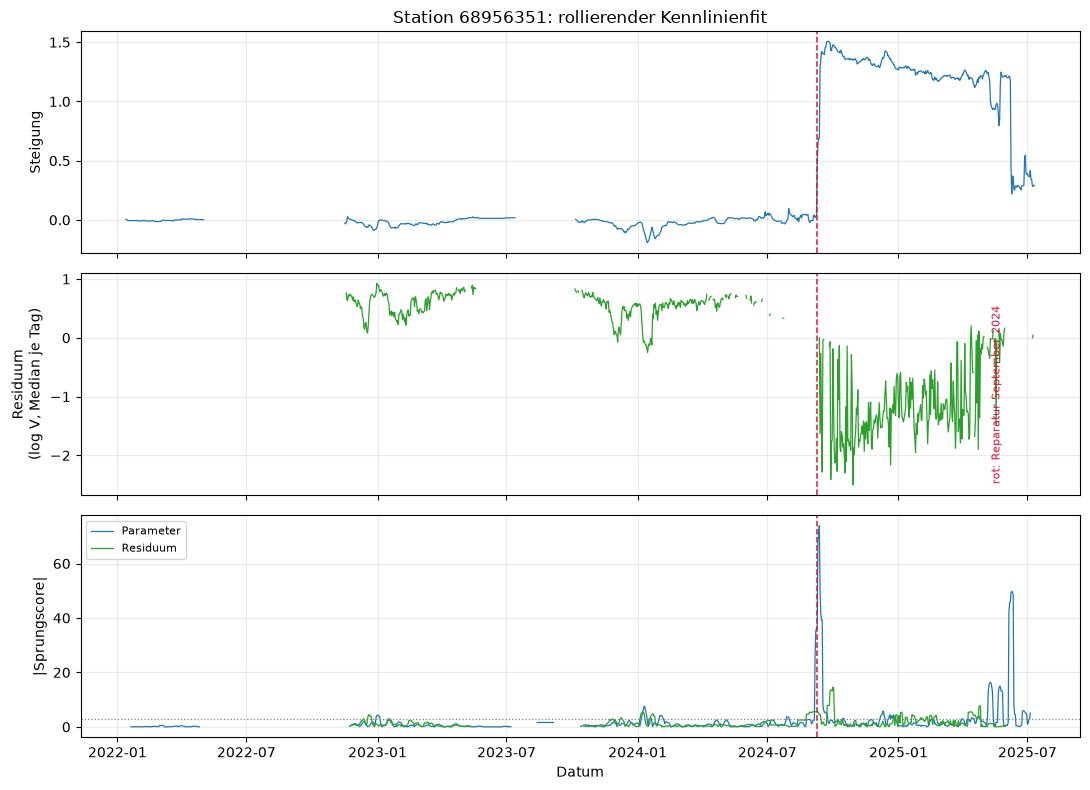

In [4]:
f = e_bsp["fenster"].copy()
f["score"] = km.sprungscore(f["steigung"].to_numpy(dtype=float))
r = e_bsp["residuum"].copy()
r["score"] = km.sprungscore(r["residuum_median"].to_numpy(dtype=float))

fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
ax[0].plot(f["datum"], f["steigung"], lw=0.9, color="#1f77b4")
ax[0].set_ylabel("Steigung")
ax[0].set_title(f"Station {BEISPIEL}: rollierender Kennlinienfit")
ax[1].plot(r["datum"], r["residuum_median"], lw=0.9, color="#2ca02c")
ax[1].set_ylabel("Residuum\n(log V, Median je Tag)")
ax[2].plot(f["datum"], f["score"].abs(), lw=0.9, color="#1f77b4",
           label="Parameter")
ax[2].plot(r["datum"], r["score"].abs(), lw=0.9, color="#2ca02c",
           label="Residuum")
ax[2].axhline(km.ALARM_SCHWELLE, color="grey", ls=":", lw=0.9)
ax[2].set_ylabel("|Sprungscore|")
ax[2].legend(loc="upper left", fontsize=8)
for a in ax:
    a.axvline(BEISPIEL_DATUM, color="crimson", ls="--", lw=1.1)
    a.grid(alpha=0.25)
ax[2].set_xlabel("Datum")
fig.text(0.905, 0.5, "rot: Reparatur September 2024", rotation=90,
         va="center", fontsize=8, color="crimson")
fig.tight_layout()
plt.show()

In [5]:
nah = al[(al["datum"] >= BEISPIEL_DATUM - pd.Timedelta(days=45)) &
         (al["datum"] <= BEISPIEL_DATUM + pd.Timedelta(days=45))]
print("Alarme im Umfeld der Reparatur:")
print(nah.to_string(index=False) if len(nah) else "keine")

rest = al[~al.index.isin(nah.index)]
print(f"\nalle uebrigen Alarme: |Score| von "
      f"{rest['score'].abs().min():.1f} bis {rest['score'].abs().max():.1f}")

Alarme im Umfeld der Reparatur:
   meter    quelle        kennzahl      datum      score richtung
68956351 parameter        steigung 2024-07-28   3.674605     hoch
68956351 parameter        steigung 2024-09-12  73.955304     hoch
68956351 parameter        steigung 2024-10-15  -3.160425   runter
68956351  residuum residuum_median 2024-08-31  -5.339846   runter
68956351  residuum residuum_median 2024-10-01 -14.631956   runter

alle uebrigen Alarme: |Score| von 3.4 bis 49.7


- Parameterkanal: größter Ausschlag der ganzen Historie (rund 74) drei Tage nach dem Termin. Der Residuenkanal schlägt kurz davor und kurz danach an (−5,3 und −14,6).
- Die Referenzsteigung ist praktisch null. Das passt zum dauerhaft offenen Ventil.
- Der zweitgrößte Alarm (knapp 50, Juni 2025) ist ungeklärt. Ein hoher Score heißt also nicht sicher Begehung oder Defekt.

## 3 Warum ein festes Fenster im Sommer blind ist

- Im Hochsommer läuft die Station nur wenige Stunden am Tag. Ein 14-Tage-Fenster hat dann zu wenige Punkte für den Fit und bleibt leer.
- Genau vor dem Termin fehlt so die Vorher-Seite, und der Fall wird übersehen.
- Lösung: Das Fenster wird breiter, bis 30 Punkte zusammenkommen, höchstens auf 60 Tage.

In [6]:
tab = sb.punkttabelle(serien[BEISPIEL], BEISPIEL, aufloesung="stunde")
betrieb = tab[(tab["power_kw"] > 0) & (tab["flow_lh"] > 0) &
              (tab["dt_k"] > 0)].copy()
betrieb["monat"] = pd.to_datetime(betrieb["zeit"]).dt.to_period("M")
je_monat = betrieb.groupby("monat").size()
print("Betriebsstunden je Monat, Mai bis Oktober 2024:")
print(je_monat[je_monat.index >= pd.Period("2024-05")].head(6).to_string())
print(f"\nzum Vergleich Januar 2024: {je_monat.get(pd.Period('2024-01'), 0)}")

Betriebsstunden je Monat, Mai bis Oktober 2024:
monat
2024-05    101
2024-06     87
2024-07     57
2024-08     61
2024-09    109
2024-10    310
Freq: M

zum Vergleich Januar 2024: 668


Fenster Jul bis Sep 2024: 92, davon ohne Fit: 0
Fensterbreite dort: Median 15, Maximum 19 Tage

ueber die ganze Historie gedehnt (> 14 Tage): 0.389 der Fenster
mittlere Fensterbreite je Kalendermonat:
monat
1     24.7
2     22.8
3     22.3
4     23.4
5     25.4
6     30.7
7     33.8
8     25.7
9     26.3
10    21.9
11    21.2
12    21.2


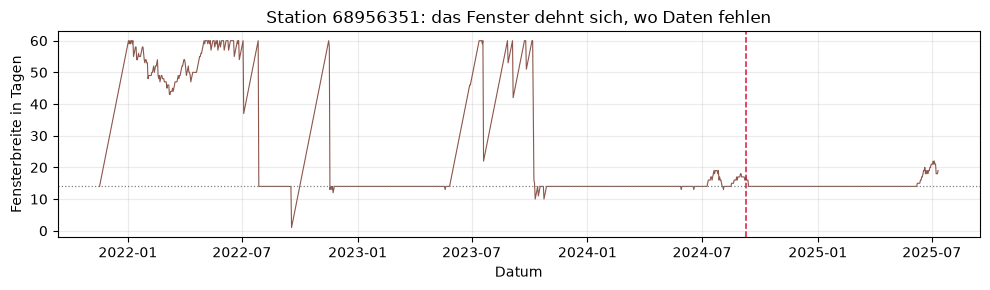

In [7]:
sommer = f[(f["datum"] >= "2024-07-01") & (f["datum"] <= "2024-09-30")]
print(f"Fenster Jul bis Sep 2024: {len(sommer)}, "
      f"davon ohne Fit: {int(sommer['steigung'].isna().sum())}")
print(f"Fensterbreite dort: Median {sommer['breite_tage'].median():.0f}, "
      f"Maximum {sommer['breite_tage'].max():.0f} Tage")

print(f"\nueber die ganze Historie gedehnt (> {km.FENSTER_TAGE} Tage): "
      f"{(f['breite_tage'] > km.FENSTER_TAGE).mean():.3f} der Fenster")
je_monat_breite = (f.assign(monat=pd.to_datetime(f["datum"]).dt.month)
                   .groupby("monat")["breite_tage"].mean().round(1))
print("mittlere Fensterbreite je Kalendermonat:")
print(je_monat_breite.to_string())

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(f["datum"], f["breite_tage"], lw=0.8, color="#8c564b")
ax.axhline(km.FENSTER_TAGE, color="grey", ls=":", lw=0.9)
ax.axvline(BEISPIEL_DATUM, color="crimson", ls="--", lw=1.1)
ax.set_ylabel("Fensterbreite in Tagen")
ax.set_xlabel("Datum")
ax.set_title(f"Station {BEISPIEL}: das Fenster dehnt sich, wo Daten fehlen")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

- Mittlere Fensterbreite im Juli 34 Tage, im November 21. Gut ein Drittel aller Fenster (0,389) ist gedehnt.
- Im Sommer 2024 bleibt damit keines der 92 Fenster zwischen Juli und September ohne Fit.
- Nachteil: Sprünge im Sommer werden ungenauer datiert.

## 4 Lauf über alle Stationen

- Dieselben Parameter für alle Zählerreihen, keine Anpassung je Station.

In [8]:
t2 = time.time()
erg = km.monitor_alle(serien, fortschritt=False)
print(f"Vollauf in {time.time() - t2:.0f} s")
print({k: len(v) for k, v in erg.items()})

alarme = erg["alarme"]
abdeckung = erg["abdeckung"]
print("\nAlarme je Kanal:")
print(alarme.groupby("quelle").size().to_string())
print("\nAlarme je Station und Kanal:")
print(alarme.groupby(["quelle", "meter"]).size()
      .groupby("quelle").describe().round(2).to_string())

Vollauf in 10 s
{'fenster': 85782, 'residuum': 86978, 'alarme': 1141, 'abdeckung': 93}

Alarme je Kanal:
quelle
parameter    645
residuum     496

Alarme je Station und Kanal:
           count  mean   std  min  25%  50%   75%   max
quelle                                                 
parameter   92.0  7.01  3.37  1.0  4.0  7.0  10.0  14.0
residuum    90.0  5.51  2.69  1.0  4.0  5.0   7.0  13.0


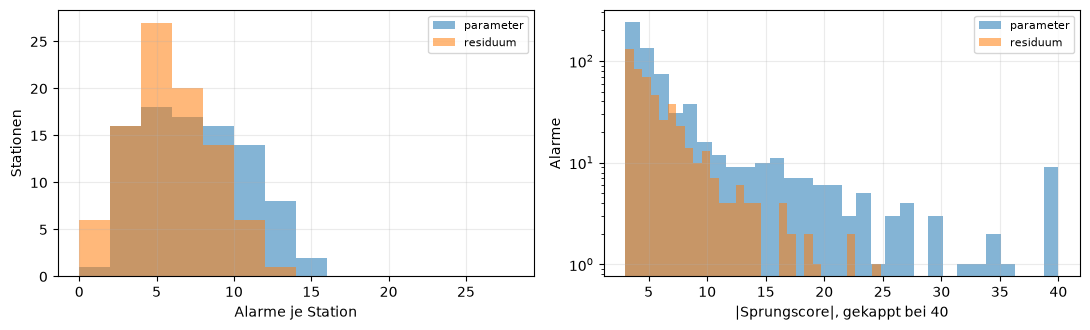

1141 Alarme auf 238 Stationsjahren, also rund 4.8 Alarme je Station und Jahr


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for i, q in enumerate(sorted(alarme["quelle"].unique())):
    teil = alarme[alarme["quelle"] == q]
    je_station = teil.groupby("meter").size()
    ax[0].hist(je_station, bins=range(0, 30, 2), alpha=0.55, label=q)
    ax[1].hist(teil["score"].abs().clip(upper=40), bins=30, alpha=0.55,
               label=q)
ax[0].set_xlabel("Alarme je Station")
ax[0].set_ylabel("Stationen")
ax[0].legend(fontsize=8)
ax[1].set_xlabel("|Sprungscore|, gekappt bei 40")
ax[1].set_ylabel("Alarme")
ax[1].set_yscale("log")
ax[1].legend(fontsize=8)
for a in ax:
    a.grid(alpha=0.25)
fig.tight_layout()
plt.show()

jahre = abdeckung["tage"].sum() / 365.25
print(f"{len(alarme)} Alarme auf {jahre:.0f} Stationsjahren, "
      f"also rund {len(alarme) / jahre:.1f} Alarme je Station und Jahr")

- 1.141 Alarme auf 238 Stationsjahren, knapp fünf je Station und Jahr über beide Kanäle.
- Für eine Vorsortierung von 93 Stationen ist das handhabbar. Ob das im Betrieb tragbar ist, sagen die Daten nicht.

## 5 Gegenprobe gegen die Begehungstermine

- Frage: Liegt häufiger als zufällig ein Alarm höchstens 30 Tage neben einem Begehungstermin?
- Die Zufallsbasis wird je Station aus Alarmzahl und Länge der Historie berechnet. Sonst trifft eine Station mit vielen Alarmen fast jeden Termin.
- Hebel = Trefferquote geteilt durch Zufallsquote. Über 1 heißt besser als Zufall.
- Der p-Wert kommt aus einem Binomialtest: Wie wahrscheinlich sind so viele Treffer, wenn nur der Zufall wirkt?

In [10]:
beobachtet = set(abdeckung["meter"].astype(int))
termine_b = {m: t for m, t in termine.items() if m in beobachtet}
print(f"{len(termine_b)} Begehungsstationen mit Monitorhistorie, "
      f"{sum(len(v) for v in termine_b.values())} Faelle")

pruef = km.validiere(alarme, termine_b)
quote = km.trefferquote(pruef)
basis = km.zufallsbasis(alarme, abdeckung, termine_b)
vergleich = quote.merge(basis, on=["quelle", "kennzahl"], how="left")
vergleich["hebel"] = (vergleich["quote"] /
                      vergleich["erwartete_quote"]).round(2)
vergleich["p"] = [
    round(float(stats.binomtest(int(r["treffer"]), int(r["faelle"]),
                                float(r["erwartete_quote"]),
                                alternative="greater").pvalue), 4)
    for _, r in vergleich.iterrows()]
print()
print(vergleich.round(3).to_string(index=False))

51 Begehungsstationen mit Monitorhistorie, 53 Faelle

   quelle        kennzahl  faelle  treffer  quote  median_abstand_tage  stationen  alarme_je_station  erwartete_quote  hebel     p
parameter        steigung      53       25  0.472                  8.0         51              6.824            0.377   1.25 0.100
 residuum residuum_median      53       21  0.396                  9.0         51              5.078            0.296   1.34 0.077


In [11]:
tr = pruef[pruef["treffer"]]
print("Abstand der Treffer zum Begehungstermin, in Tagen:")
print(tr.groupby("quelle")["abstand_tage"].describe().round(1).to_string())

Abstand der Treffer zum Begehungstermin, in Tagen:
           count  mean   std   min  25%  50%   75%   max
quelle                                                  
parameter   25.0   2.1  13.3 -29.0 -4.0  3.0  13.0  28.0
residuum    21.0   3.5  11.7 -19.0 -7.0  6.0  10.0  24.0


- Parameterkanal 25 von 53 (Hebel 1,25, p = 0,10), Residuenkanal 21 von 53 (Hebel 1,34, p = 0,077). Die Richtung stimmt, der Abstand zum Zufall ist aber knapp.
- Die Treffer streuen über das ganze Toleranzfenster, im Median um eine Woche.

## 6 Hängt das Ergebnis an der Schwelle?

- Trägt der Score Information über Eingriffe, sollte der Hebel bei stärkeren Ausschlägen steigen.
- Geprüft über mehrere Schwellen und über nur die stärksten Alarme je Station.

In [12]:
fenster_all = erg["fenster"]
resid_all = erg["residuum"]
KANAELE = [(km.QUELLE_PARAMETER, "steigung", fenster_all, "score_steigung"),
           (km.QUELLE_RESIDUUM, "residuum_median", resid_all,
            "score_residuum")]


def baue(schwelle, topk=None):
    teile = []
    for quelle, kennzahl, frame, spalte in KANAELE:
        for meter, teil in frame.groupby("meter"):
            a = km.alarme(teil["datum"], teil[spalte], schwelle=schwelle)
            if not len(a):
                continue
            if topk is not None:
                a = a.reindex(a["score"].abs().sort_values(ascending=False)
                              .index).head(topk)
            teile.append(a.assign(meter=int(meter), quelle=quelle,
                                  kennzahl=kennzahl))
    return pd.concat(teile, ignore_index=True) if teile else pd.DataFrame()


zeilen = []
for schwelle, topk in [(3.0, None), (4.0, None), (5.0, None), (6.0, None),
                       (8.0, None), (3.0, 3), (3.0, 2), (3.0, 1)]:
    al_s = baue(schwelle, topk)
    z = (km.trefferquote(km.validiere(al_s, termine_b))
         .merge(km.zufallsbasis(al_s, abdeckung, termine_b),
                on=["quelle", "kennzahl"], how="left"))
    for _, r in z.iterrows():
        n, k, p = int(r["faelle"]), int(r["treffer"]), float(r["erwartete_quote"])
        zeilen.append({"schwelle": schwelle, "topk": topk or 0,
                       "quelle": r["quelle"],
                       "alarme_je_station": round(
                           float(r["alarme_je_station"]), 2),
                       "faelle": n, "treffer": k,
                       "quote": round(k / n, 3) if n else np.nan,
                       "zufall": round(p, 3),
                       "hebel": round((k / n) / p, 2) if n and p else np.nan,
                       "p": round(float(stats.binomtest(
                           k, n, p, alternative="greater").pvalue), 4)})

sweep = pd.DataFrame(zeilen)
print(sweep.to_string(index=False))

 schwelle  topk    quelle  alarme_je_station  faelle  treffer  quote  zufall  hebel      p
      3.0     0 parameter               6.82      53       25  0.472   0.377   1.25 0.1005
      3.0     0  residuum               5.08      53       21  0.396   0.296   1.34 0.0766
      4.0     0 parameter               4.63      53       19  0.358   0.259   1.38 0.0717
      4.0     0  residuum               3.55      53       18  0.340   0.214   1.58 0.0241
      5.0     0 parameter               3.29      53       16  0.302   0.183   1.65 0.0245
      5.0     0  residuum               2.47      53       12  0.226   0.147   1.54 0.0817
      6.0     0 parameter               2.63      53       13  0.245   0.149   1.64 0.0447
      6.0     0  residuum               1.84      53       10  0.189   0.110   1.71 0.0613
      8.0     0 parameter               1.80      53       11  0.208   0.098   2.13 0.0122
      8.0     0  residuum               0.94      53        4  0.075   0.053   1.42 0.3097

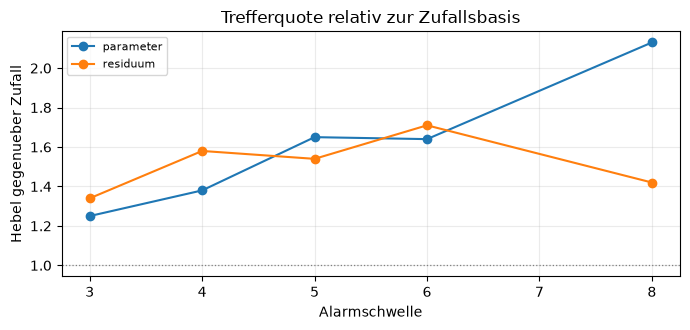

staerkster Alarm je Station:
 schwelle  topk    quelle  alarme_je_station  faelle  treffer  quote  zufall  hebel      p
      3.0     1 parameter               1.00      53        4  0.075   0.085   0.89 0.6721
      3.0     1  residuum               0.96      53        7  0.132   0.079   1.68 0.1199


In [13]:
nur_schwelle = sweep[sweep["topk"] == 0]
fig, ax = plt.subplots(figsize=(7, 3.4))
for q, teil in nur_schwelle.groupby("quelle"):
    ax.plot(teil["schwelle"], teil["hebel"], marker="o", label=q)
ax.axhline(1.0, color="grey", ls=":", lw=0.9)
ax.set_xlabel("Alarmschwelle")
ax.set_ylabel("Hebel gegenueber Zufall")
ax.set_title("Trefferquote relativ zur Zufallsbasis")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

print("staerkster Alarm je Station:")
print(sweep[sweep["topk"] == 1].to_string(index=False))

- Parameterkanal: Der Hebel steigt mit der Schwelle von 1,25 auf rund 2,1 (kleinstes p 0,012). Bei sechzehn Einstellungen zählt das Muster, nicht das einzelne p.
- Residuenkanal: am stärksten bei Schwelle 4 bis 6 (Hebel 1,58, 1,54 und 1,71), bei Schwelle 8 nur 1,42.
- Nur der stärkste Alarm je Station: Parameterkanal 4 von 53, schlechter als Zufall. Die größten Sprünge der Steigung sind meist keine Begehungen. Zählertausch oder ein Wechsel der Messauflösung kommen in Frage, sind aber nicht geprüft.

## 7 Trifft der Monitor die Begehungen mit Eingriff?

- Eingriff heißt: Alt- und Neu-Wert im Protokoll unterscheiden sich bei Heizzeit, Trinkwarmwasser oder Sollwerten.
- Diese Einteilung ist unabhängig vom Monitor.

In [14]:
beg = lb.begehungen_mit_zaehler()
beg = beg[beg["meter"].notna() & beg["datum"].notna()].copy()
beg["meter"] = beg["meter"].astype(int)
beg = beg[beg["meter"].isin(beobachtet)]

PAARE = [("heizzeit_alt_von", "heizzeit_neu_von"),
         ("heizzeit_alt_bis", "heizzeit_neu_bis"),
         ("tww_alt_von", "tww_neu_von"),
         ("tww_alt_bis", "tww_neu_bis"),
         ("rw_soll_tag_alt", "rw_soll_tag_neu"),
         ("rw_soll_nacht_alt", "rw_soll_nacht_neu"),
         ("tww_soll_alt", "tww_soll_neu")]


def geaendert(zeile):
    for alt, neu in PAARE:
        a, n = zeile.get(alt), zeile.get(neu)
        if pd.isna(a) or pd.isna(n):
            continue
        if str(a).strip() != str(n).strip():
            return True
    return False


beg["eingriff"] = beg.apply(geaendert, axis=1)
print(beg["eingriff"].value_counts().to_string())

zeilen = []
for flag in (True, False):
    teil = beg[beg["eingriff"] == flag]
    t_split = {}
    for m, d in zip(teil["meter"], teil["datum"]):
        t_split.setdefault(int(m), []).append(d)
    z = (km.trefferquote(km.validiere(alarme, t_split))
         .merge(km.zufallsbasis(alarme, abdeckung, t_split),
                on=["quelle", "kennzahl"], how="left"))
    for _, r in z.iterrows():
        n, k, p = int(r["faelle"]), int(r["treffer"]), float(r["erwartete_quote"])
        zeilen.append({"eingriff": flag, "quelle": r["quelle"],
                       "faelle": n, "treffer": k,
                       "quote": round(k / n, 3) if n else np.nan,
                       "zufall": round(p, 3),
                       "hebel": round((k / n) / p, 2) if n and p else np.nan,
                       "p": round(float(stats.binomtest(
                           k, n, p, alternative="greater").pvalue), 4)})

print()
print(pd.DataFrame(zeilen).to_string(index=False))

eingriff
True     39
False    14



 eingriff    quelle  faelle  treffer  quote  zufall  hebel      p
     True parameter      39       17  0.436   0.383   1.14 0.3009
     True  residuum      39       16  0.410   0.284   1.44 0.0614
    False parameter      14        8  0.571   0.363   1.57 0.0917
    False  residuum      14        5  0.357   0.328   1.09 0.5064


/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


- Der Parameterkanal zeigt das Gegenteil der Erwartung: ohne Eingriff Hebel 1,57, mit Eingriff 1,14.
- Der Residuenkanal zeigt leicht in die erwartete Richtung (mit Eingriff 1,44, ohne 1,09). Es gibt aber nur 14 Fälle ohne Eingriff.
- Zwei Erklärungen sind möglich: Die Alarme sind überwiegend Rauschen, oder die Alt-Neu-Spalten geben den Eingriff nicht wieder. Für das Zweite spricht, dass die Reparatur bei 68956351 dort fehlt.

## Zusammenfassung & Bewertung

**Ergebnis**
- Die Kennlinie funktioniert als eigenes Modell für alle 93 Stationen.
- Im einzigen bekannten Fall kommt der größte Ausschlag drei Tage nach der Reparatur.
- Gegen alle Begehungen treffen die Alarme 25 bis 34 % häufiger als Zufall (Hebel 1,25 und 1,34, p = 0,10 und 0,077).

**Belastbar**
- Der Mechanismus: Die Sommerlücke ist über das dehnbare Fenster behoben. Der bekannte Fall steckt als Regressionstest im Code.

**Schwach**
- Der Abstand zum Zufall ist knapp, und der stärkste Alarm je Station trifft schlechter als Zufall.
- Mit den kodierten Freitexten aus Notebook 14 trifft der Residuenkanal mechanische Eingriffe in 10 von 19 Fällen (0,526 gegen Zufall 0,296, p = 0,030). Das ist ein Hinweis, dass der schwache Gesamtbefund zum Teil am Maßstab liegt.

**Offen**
- Die Schwellen sind gesetzt, nicht hergeleitet.
- Einfluss von Zählertausch und dem nicht dokumentierten Wechsel der Messauflösung vor November 2022.
- Stillstand sieht der Monitor nicht. Das gehört in die Abdeckungstabelle.